In [1]:
# Importation des bibliothèques nécessaires
import os
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

In [2]:
# CHECK DATA DIRECTORIES: Vérification des dossiers de données
DEPARTMENTS = [61, 69]

# Définition du répertoire racine contenant les données
DATA_ROOT = Path(".")

# Affichage du répertoire de travail en cours
print("Using working directory:", DATA_ROOT.resolve())

# Vérification de l’existence des dossiers pour chaque département
for dept in DEPARTMENTS:
    folder = DATA_ROOT / f"DEPT_{dept}"
    if not folder.exists():
        raise FileNotFoundError(
            f"Expected folder not found: {folder.resolve()}"
        )
    else:
        print(f"Found department folder: {folder.resolve()}")

Using working directory: C:\Users\Lenovo\Desktop\TP
Found department folder: C:\Users\Lenovo\Desktop\TP\DEPT_61
Found department folder: C:\Users\Lenovo\Desktop\TP\DEPT_69


In [3]:
# LOAD DATA: Chargement des données des stations pour un département
def load_station_data(dept: int) -> dict:
    # Définition du motif de fichiers à lire
    pattern = DATA_ROOT / f"DEPT_{dept}" / f"DEPT_{dept}_STATION_*.csv"
    frames = {}

    # Lecture des fichiers CSV triés
    for f in sorted(glob.glob(str(pattern))):
        station_id = os.path.basename(f).split("_STATION_")[1].split(".")[0]
        df = pd.read_csv(f, sep=";", parse_dates=["AAAAMMJJHH"])

        # Vérification de la présence de la variable cible
        if "T" not in df.columns:
            continue

        # Nettoyage et tri des données
        df = df[["AAAAMMJJHH", "T"]].dropna().sort_values("AAAAMMJJHH").reset_index(drop=True)

        # Ajout de l'identifiant de station
        df["station_id"] = station_id
        frames[station_id] = df

    # Résumé du chargement
    print(f"Department {dept}: loaded {len(frames)} stations.")
    return frames

station_raw = {dept: load_station_data(dept) for dept in DEPARTMENTS}

Department 61: loaded 23 stations.
Department 69: loaded 25 stations.


In [4]:
# FEATURE ENGINEERING: Ajout des variables temporelles et des décalages

# Ajoute des variables basées sur la date et l'heure
def add_time_features(df: pd.DataFrame) -> pd.DataFrame:
    ts = pd.to_datetime(df["AAAAMMJJHH"])
    df["hour"] = ts.dt.hour        
    df["day"] = ts.dt.day          
    df["month"] = ts.dt.month      
    df["weekday"] = ts.dt.weekday  

    # Encodage cyclique de l'heure
    df["sin_hour"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["cos_hour"] = np.cos(2 * np.pi * df["hour"] / 24)

    return df

# Ajoute des retards temporels et une moyenne glissante
def add_lag_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.sort_values(["station_id", "AAAAMMJJHH"]) 

    df["T_lag1"] = df.groupby("station_id")["T"].shift(1)     
    df["T_lag24"] = df.groupby("station_id")["T"].shift(24)   

    df["T_rollmean_24"] = df.groupby("station_id")["T"].transform(
        lambda x: x.rolling(window=24, min_periods=1).mean()
    )

    # Suppression des lignes incomplètes
    return df.dropna(subset=["T_lag1", "T_lag24", "T_rollmean_24"]).reset_index(drop=True)

# Applique les transformations à chaque station de chaque département
station_fe = {}
for dept, stations in station_raw.items():
    station_fe[dept] = {}
    for sid, df in stations.items():
        fe = add_time_features(df.copy())  # Ajout des variables temporelles
        fe = add_lag_features(fe)          # Ajout des décalages
        station_fe[dept][sid] = fe

    print(f"Department {dept}: feature-engineered {len(stations)} stations.")

Department 61: feature-engineered 23 stations.
Department 69: feature-engineered 25 stations.


In [5]:
# TRAIN/TEST SPLIT AND SCALING: Préparation des jeux locaux et normalisation

# Sépare les données d'une station en train/test
def time_split(df: pd.DataFrame, train_ratio: float = 0.8):
    df = df.sort_values("AAAAMMJJHH")  
    split_idx = int(len(df) * train_ratio)  

    train_df = df.iloc[:split_idx]   
    test_df = df.iloc[split_idx:]    

    # Colonnes utilisées comme variables explicatives
    feature_cols = [c for c in df.columns if c not in ["AAAAMMJJHH", "T", "station_id"]]

    return train_df, test_df, feature_cols


# Création des clients FL et normalisation partagée
clients, scalers, feature_cols_map = {}, {}, {}

for dept, stations in station_fe.items():
    all_train = []      # Contiendra toutes les features pour fit du scaler commun
    dept_clients = []   # Liste des clients du département
    feature_cols = None

    # Construction des datasets locaux pour chaque station
    for sid, df in stations.items():
        train_df, test_df, feature_cols = time_split(df)

        all_train.append(train_df[feature_cols].values)  # Accumulation des données pour scaler

        dept_clients.append({
            "station_id": sid,
            "train_df": train_df,
            "test_df": test_df,
            "X_train_raw": train_df[feature_cols].values,
            "X_test_raw": test_df[feature_cols].values,
            "y_train": train_df["T"].values,
            "y_test": test_df["T"].values
        })

    # Normalisation commune à toutes les stations du département
    scaler = StandardScaler().fit(np.vstack(all_train))
    scalers[dept] = scaler
    feature_cols_map[dept] = feature_cols

    # Transformation des données locales
    for c in dept_clients:
        c["X_train"] = scaler.transform(c.pop("X_train_raw"))  
        c["X_test"] = scaler.transform(c.pop("X_test_raw"))    
        c["n_train"] = len(c["y_train"])                      
        c["n_test"] = len(c["y_test"])                        

    clients[dept] = dept_clients
    print(f"Department {dept}: {len(dept_clients)} clients ready with shared scaler.")

Department 61: 23 clients ready with shared scaler.
Department 69: 25 clients ready with shared scaler.


In [6]:
# FEDERATED LINEAR REGRESSION: Entraînement fédéré LR (FedAvg et FedProx)

# Calcule la prédiction d'un modèle linéaire
def eval_lr(w, b, X):
    return X @ w + b

# Effectue FedAvg ou FedProx pour la régression linéaire
def run_federated_lr_closed(dept_clients, rounds=3, mu=0.0):
    n_features = dept_clients[0]["X_train"].shape[1]  # Nombre de variables explicatives
    global_w = np.zeros(n_features)   # Poids globaux initiaux
    global_b = 0.0                    # Interception globale initiale
    history = []                      # Historique des erreurs

    # Boucle des rondes fédérées
    for r in range(rounds):
        local_params = []  # Liste des modèles locaux
        weights = []       # Liste des poids 

        # Entraînement de chaque client
        for c in dept_clients:
            lr = LinearRegression()
            lr.fit(c["X_train"], c["y_train"])  

            w_loc = lr.coef_.astype(float)
            b_loc = float(lr.intercept_)

            w_loc = w_loc - mu * (w_loc - global_w)
            b_loc = b_loc - mu * (b_loc - global_b)

            local_params.append((w_loc, b_loc))
            weights.append(c["n_train"])

        # Agrégation FedAvg pondérée par le nombre d'échantillons
        total = sum(weights)
        global_w = sum(w * (n / total) for (w, _), n in zip(local_params, weights))
        global_b = sum(b * (n / total) for (_, b), n in zip(local_params, weights))

        # Évaluation globale sur les données locales
        round_mse = np.mean([
            mean_squared_error(c["y_train"], eval_lr(global_w, global_b, c["X_train"]))
            for c in dept_clients
        ])

        history.append(round_mse)
        print(f"Round {r+1}/{rounds}: train MSE {round_mse:.4f}")

    return global_w, global_b, history

In [7]:
# FEDERATED LR EVALUATION: Évaluation FedAvg et FedProx pour la régression linéaire
LR_ROUNDS = 3            # Nombre de rondes fédérées
FEDPROX_MU = 0.1         # Hyperparamètre FedProx

lr_results = {}          # Dictionnaire pour stocker les résultats LR

# Parcours des départements et exécution des deux variantes (FedAvg et FedProx)
for dept, dept_clients in clients.items():

    # FedAvg (mu = 0)
    print(f"\nDepartment {dept}: FedAvg LR")
    w_avg, b_avg, hist_avg = run_federated_lr_closed(
        dept_clients,
        rounds=LR_ROUNDS,
        mu=0.0
    )

    # FedProx (mu > 0)
    print(f"\nDepartment {dept}: FedProx LR (mu={FEDPROX_MU})")
    w_prox, b_prox, hist_prox = run_federated_lr_closed(
        dept_clients,
        rounds=LR_ROUNDS,
        mu=FEDPROX_MU
    )

    # Calcul des métriques station-par-station
    records = []
    for c in dept_clients:
        y_pred_avg = eval_lr(w_avg, b_avg, c["X_test"])    # Prédiction FedAvg
        y_pred_prox = eval_lr(w_prox, b_prox, c["X_test"]) # Prédiction FedProx

        records.append({
            "station_id": c["station_id"],
            "n_train": c["n_train"],
            "n_test": c["n_test"],
            "mse_lr_fedavg": mean_squared_error(c["y_test"], y_pred_avg),
            "r2_lr_fedavg": r2_score(c["y_test"], y_pred_avg),
            "mse_lr_fedprox": mean_squared_error(c["y_test"], y_pred_prox),
            "r2_lr_fedprox": r2_score(c["y_test"], y_pred_prox)
        })

    # Conversion en DataFrame
    df_res = pd.DataFrame(records)
    lr_results[dept] = df_res

    # Affichage d’un aperçu
    display(df_res.head())


Department 61: FedAvg LR
Round 1/3: train MSE 0.7629
Round 2/3: train MSE 0.7629
Round 3/3: train MSE 0.7629

Department 61: FedProx LR (mu=0.1)
Round 1/3: train MSE 2.4512
Round 2/3: train MSE 0.7800
Round 3/3: train MSE 0.7631


,station_id,n_train,n_test,mse_lr_fedavg,r2_lr_fedavg,mse_lr_fedprox,r2_lr_fedprox
0,61001001,250889,62723,0.767452,0.983631,0.767998,0.983619
1,61006005,219363,54841,0.867358,0.981188,0.867650,0.981182
2,61074004,73114,18279,0.721628,0.984883,0.721664,0.984882
3,61124001,1558,390,0.409985,0.947175,0.410617,0.947094
4,61133001,92986,23247,0.618995,0.985799,0.619165,0.985795



Department 69: FedAvg LR
Round 1/3: train MSE 0.9348
Round 2/3: train MSE 0.9348
Round 3/3: train MSE 0.9348

Department 69: FedProx LR (mu=0.1)
Round 1/3: train MSE 2.9963
Round 2/3: train MSE 0.9548
Round 3/3: train MSE 0.9350


,station_id,n_train,n_test,mse_lr_fedavg,r2_lr_fedavg,mse_lr_fedprox,r2_lr_fedprox
0,69008001,48339,12085,0.917086,0.985176,0.917179,0.985175
1,69023002,162893,40724,0.755242,0.987328,0.755643,0.987321
2,69028001,145915,36479,1.078368,0.984259,1.078572,0.984256
3,69029001,250889,62723,0.848138,0.987566,0.848914,0.987555
4,69058002,169651,42413,0.765250,0.986927,0.765430,0.986924


In [8]:
# FEDERATED RANDOM FOREST: Agrégation FedAvg et FedProx pour RF

# Agrège les prédictions locales en pondérant par la taille des clients
def aggregate_rf_predictions(models, weights, X, prev=None, mu=0.0):
    total = sum(weights)  # Somme des poids
    base = sum(w * m.predict(X) for m, w in zip(models, weights)) / total  # Prédiction FedAvg

    if prev is not None and mu > 0:
        return (base + mu * prev) / (1 + mu)

    return base

# Exécute l’apprentissage fédéré RF
def run_federated_rf(dept_clients, rounds=1, mu=0.0, rf_params=None):
    rf_params = rf_params or dict(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=3,
        random_state=58,
        n_jobs=-1
    )

    # Stockage des prédictions des rondes précédentes
    prev_preds = {c["station_id"]: np.zeros(len(c["y_test"])) for c in dept_clients}

    # Boucle des rondes fédérées
    for r in range(rounds):
        models, weights = [], []

        # Entraînement local de chaque Random Forest
        for c in dept_clients:
            model = RandomForestRegressor(**rf_params)
            model.fit(c["X_train"], c["y_train"]) 
            models.append(model)
            weights.append(c["n_train"])

        # Construction des nouvelles prédictions fédérées
        new_prev = {}
        for c in dept_clients:
            prev_vec = prev_preds[c["station_id"]] if r > 0 else None
            prox_pred = aggregate_rf_predictions(
                models, weights, c["X_test"], prev=prev_vec, mu=mu
            )
            new_prev[c["station_id"]] = prox_pred

        prev_preds = new_prev
        print(f"RF round {r+1}/{rounds} done.")

    return prev_preds

In [9]:
# FEDERATED RANDOM FOREST EVALUATION: Évaluation FedAvg et FedProx pour Random Forest

RF_ROUNDS = 1           
RF_PARAMS = dict(
    n_estimators=150,    
    max_depth=12,         
    min_samples_leaf=3,   
    random_state=58,      
    n_jobs=-1             
)
RF_PROX_MU = 0.1         # Hyperparamètre FedProx

rf_results = {}          # Stockage des résultats par département

# Parcours des départements et exécution FedAvg et FedProx
for dept, dept_clients in clients.items():

    # FedAvg (mu = 0)
    print(f"\nDepartment {dept}: FedAvg RF")
    preds_fedavg = run_federated_rf(
        dept_clients,
        rounds=RF_ROUNDS,
        mu=0.0,
        rf_params=RF_PARAMS
    )

    # FedProx (mu > 0)
    print(f"\nDepartment {dept}: FedProx RF (mu={RF_PROX_MU})")
    preds_fedprox = run_federated_rf(
        dept_clients,
        rounds=RF_ROUNDS,
        mu=RF_PROX_MU,
        rf_params=RF_PARAMS
    )

    # Calcul des métriques station-par-station
    records = []
    for c in dept_clients:
        y_pred_avg = preds_fedavg[c["station_id"]]     # Prédictions FedAvg
        y_pred_prox = preds_fedprox[c["station_id"]]   # Prédictions FedProx

        records.append({
            "station_id": c["station_id"],
            "mse_rf_fedavg": mean_squared_error(c["y_test"], y_pred_avg),
            "r2_rf_fedavg": r2_score(c["y_test"], y_pred_avg),
            "mse_rf_fedprox": mean_squared_error(c["y_test"], y_pred_prox),
            "r2_rf_fedprox": r2_score(c["y_test"], y_pred_prox)
        })

    # Conversion des résultats en DataFrame
    rf_results[dept] = pd.DataFrame(records)

    # Affichage d’un aperçu
    display(rf_results[dept].head())


Department 61: FedAvg RF
RF round 1/1 done.

Department 61: FedProx RF (mu=0.1)
RF round 1/1 done.


,station_id,mse_rf_fedavg,r2_rf_fedavg,mse_rf_fedprox,r2_rf_fedprox
0,61001001,0.577564,0.987681,0.577564,0.987681
1,61006005,0.659402,0.985698,0.659402,0.985698
2,61074004,0.560624,0.988256,0.560624,0.988256
3,61124001,0.325626,0.958045,0.325626,0.958045
4,61133001,0.477732,0.989040,0.477732,0.989040



Department 69: FedAvg RF
RF round 1/1 done.

Department 69: FedProx RF (mu=0.1)
RF round 1/1 done.


,station_id,mse_rf_fedavg,r2_rf_fedavg,mse_rf_fedprox,r2_rf_fedprox
0,69008001,0.782286,0.987355,0.782286,0.987355
1,69023002,0.644420,0.989187,0.644420,0.989187
2,69028001,0.851990,0.987563,0.851990,0.987563
3,69029001,0.672478,0.990141,0.672478,0.990141
4,69058002,0.664209,0.988653,0.664209,0.988653


In [10]:
# MERGE AND SAVE RESULTS: Fusion des résultats LR et RF, puis export CSV
combined_results = {}

# Fusion des métriques LR et RF pour chaque département
for dept in DEPARTMENTS:
    merged = lr_results[dept].merge(rf_results[dept], on="station_id")  
    combined_results[dept] = merged

    print(f"\nDepartment {dept}: Federated LR and Federated RF results")
    display(merged.head())  

# Sauvegarde des résultats finaux en fichiers CSV
for dept, df in combined_results.items():
    out_path = f"federated_results_DEPT_{dept}.csv"
    df.to_csv(out_path, index=False)
    print(f"Saved {out_path}")


Department 61: Federated LR and Federated RF results


,station_id,n_train,n_test,mse_lr_fedavg,r2_lr_fedavg,mse_lr_fedprox,r2_lr_fedprox,mse_rf_fedavg,r2_rf_fedavg,mse_rf_fedprox,r2_rf_fedprox
0,61001001,250889,62723,0.767452,0.983631,0.767998,0.983619,0.577564,0.987681,0.577564,0.987681
1,61006005,219363,54841,0.867358,0.981188,0.867650,0.981182,0.659402,0.985698,0.659402,0.985698
2,61074004,73114,18279,0.721628,0.984883,0.721664,0.984882,0.560624,0.988256,0.560624,0.988256
3,61124001,1558,390,0.409985,0.947175,0.410617,0.947094,0.325626,0.958045,0.325626,0.958045
4,61133001,92986,23247,0.618995,0.985799,0.619165,0.985795,0.477732,0.989040,0.477732,0.989040



Department 69: Federated LR and Federated RF results


,station_id,n_train,n_test,mse_lr_fedavg,r2_lr_fedavg,mse_lr_fedprox,r2_lr_fedprox,mse_rf_fedavg,r2_rf_fedavg,mse_rf_fedprox,r2_rf_fedprox
0,69008001,48339,12085,0.917086,0.985176,0.917179,0.985175,0.782286,0.987355,0.782286,0.987355
1,69023002,162893,40724,0.755242,0.987328,0.755643,0.987321,0.644420,0.989187,0.644420,0.989187
2,69028001,145915,36479,1.078368,0.984259,1.078572,0.984256,0.851990,0.987563,0.851990,0.987563
3,69029001,250889,62723,0.848138,0.987566,0.848914,0.987555,0.672478,0.990141,0.672478,0.990141
4,69058002,169651,42413,0.765250,0.986927,0.765430,0.986924,0.664209,0.988653,0.664209,0.988653


Saved federated_results_DEPT_61.csv
Saved federated_results_DEPT_69.csv


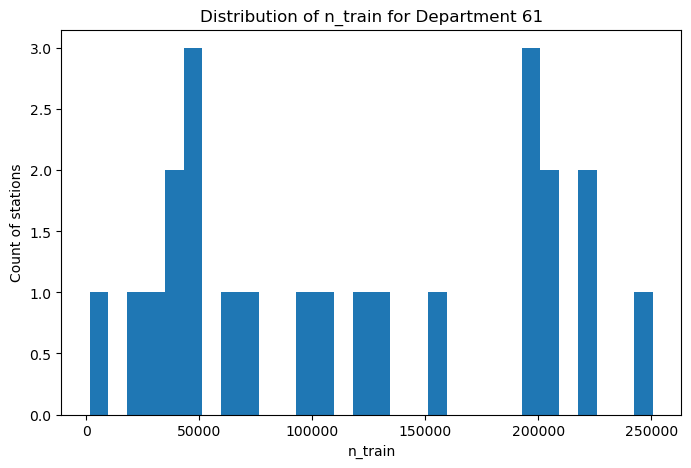

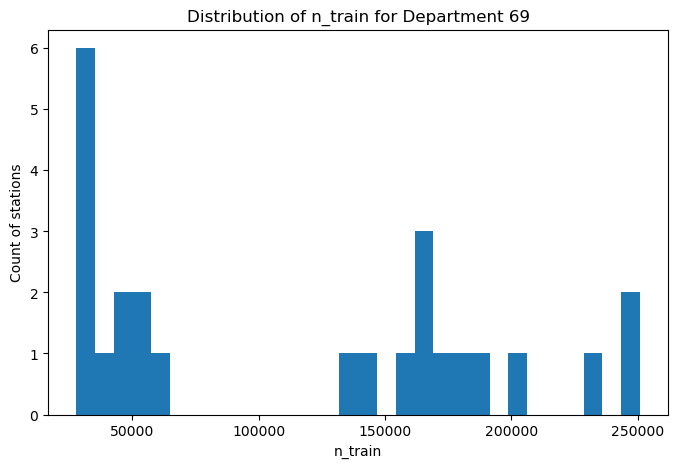

In [11]:
# TRAIN SIZE DISTRIBUTION: Distribution des tailles d'entraînement
for dept, df in lr_results.items():
    plt.figure(figsize=(8, 5))

    plt.hist(df["n_train"].values, bins=30)

    plt.xlabel("n_train")
    plt.ylabel("Count of stations")
    plt.title(f"Distribution of n_train for Department {dept}")
    plt.show()

Round 1/3: train MSE 0.7629
Round 2/3: train MSE 0.7629
Round 3/3: train MSE 0.7629
Round 1/3: train MSE 2.4512
Round 2/3: train MSE 0.7800
Round 3/3: train MSE 0.7631


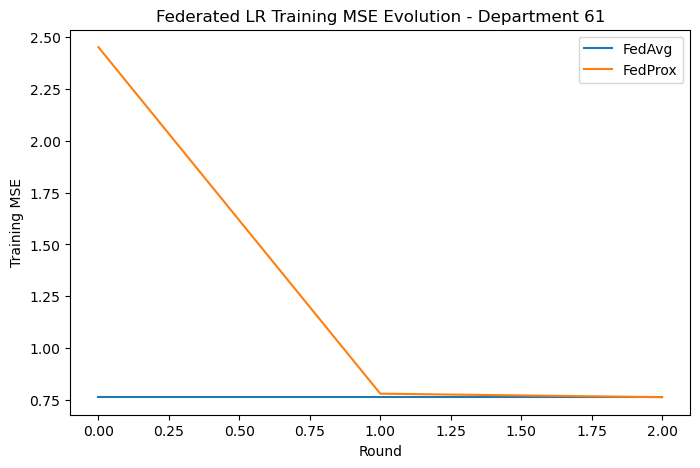

Round 1/3: train MSE 0.9348
Round 2/3: train MSE 0.9348
Round 3/3: train MSE 0.9348
Round 1/3: train MSE 2.9963
Round 2/3: train MSE 0.9548
Round 3/3: train MSE 0.9350


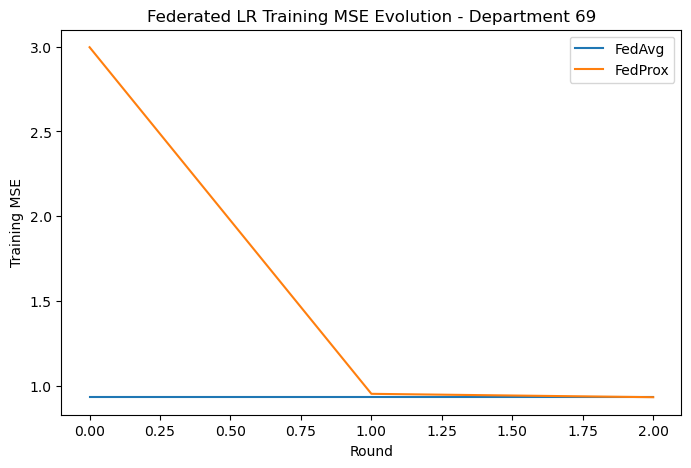

In [12]:
# LR TRAINING CURVES: Évolution du MSE pour FedAvg et FedProx
for dept, dept_clients in clients.items():
    
    # Entraînement FedAvg
    w_avg, b_avg, hist_avg = run_federated_lr_closed(
        dept_clients,
        rounds=LR_ROUNDS,
        mu=0.0
    )
    
    # Entraînement FedProx
    w_prox, b_prox, hist_prox = run_federated_lr_closed(
        dept_clients,
        rounds=LR_ROUNDS,
        mu=FEDPROX_MU
    )

    # Courbes MSE
    plt.figure(figsize=(8, 5))
    plt.plot(hist_avg, label="FedAvg")
    plt.plot(hist_prox, label="FedProx")

    plt.xlabel("Round")
    plt.ylabel("Training MSE")
    plt.title(f"Federated LR Training MSE Evolution - Department {dept}")
    plt.legend()
    plt.show()

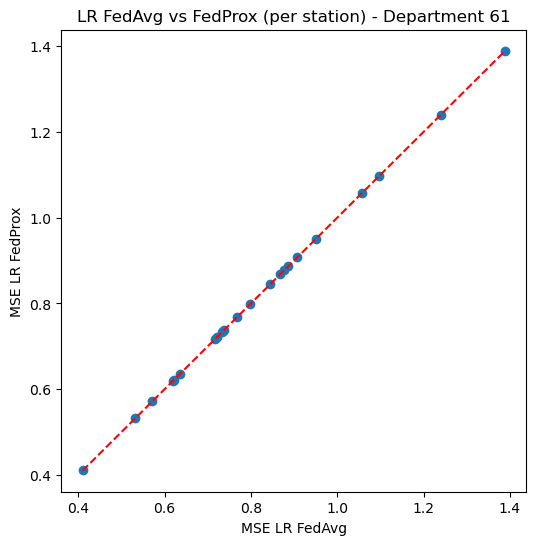

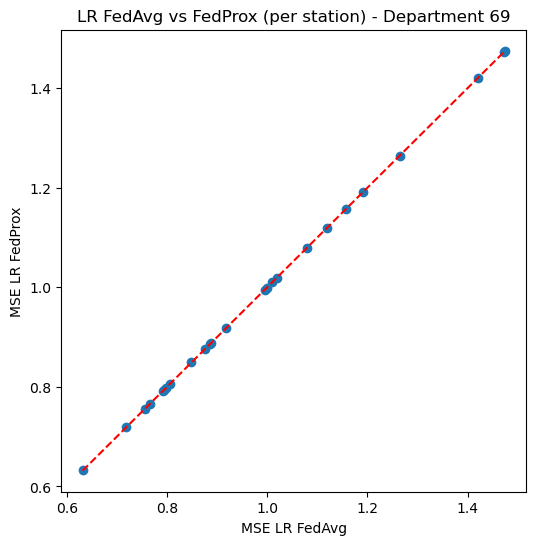

In [13]:
# LR FEDAVG VS FEDPROX COMPARISON: Comparaison MSE station-par-station
for dept, df in lr_results.items():

    x = df["mse_lr_fedavg"].values
    y = df["mse_lr_fedprox"].values

    plt.figure(figsize=(6, 6))

    plt.scatter(x, y)

    line_min = min(x.min(), y.min())
    line_max = max(x.max(), y.max())
    plt.plot([line_min, line_max], [line_min, line_max], 'r--')

    plt.xlabel("MSE LR FedAvg")
    plt.ylabel("MSE LR FedProx")
    plt.title(f"LR FedAvg vs FedProx (per station) - Department {dept}")
    plt.show()

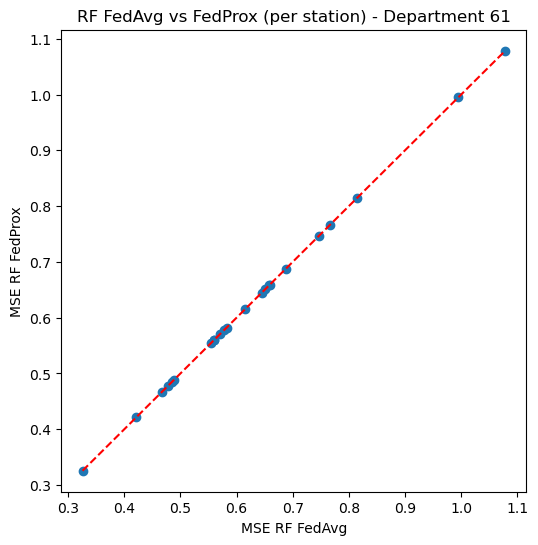

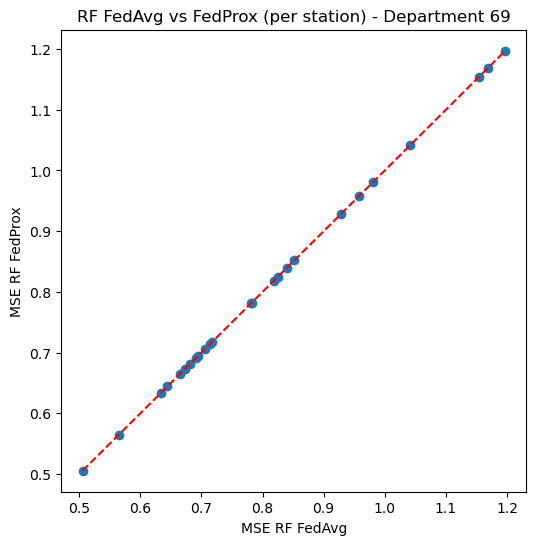

In [14]:
# RF FEDAVG VS FEDPROX COMPARISON: Comparaison des MSE RF station-par-station
for dept, df in rf_results.items():

    x = df["mse_rf_fedavg"].values
    y = df["mse_rf_fedprox"].values

    plt.figure(figsize=(6, 6))
    
    plt.scatter(x, y)

    line_min = min(x.min(), y.min())
    line_max = max(x.max(), y.max())
    plt.plot([line_min, line_max], [line_min, line_max], 'r--')

    plt.xlabel("MSE RF FedAvg")
    plt.ylabel("MSE RF FedProx")
    plt.title(f"RF FedAvg vs FedProx (per station) - Department {dept}")
    plt.show()

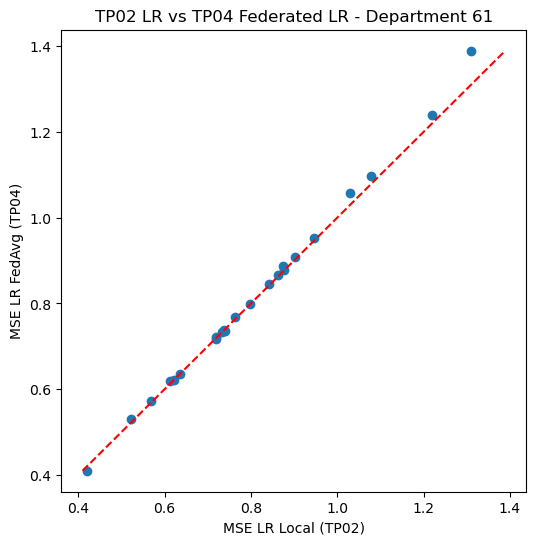

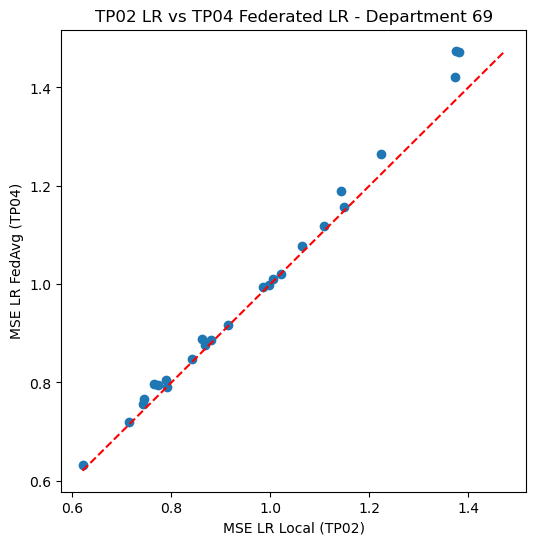

In [15]:
# TP02 VS TP04 LR COMPARISON — Comparaison des MSE locaux et fédérés
for dept in DEPARTMENTS:
    
    # Chargement des résultats TP02
    path_tp02 = f"local_results_DEPT_{dept}_TP02.csv"
    tp02 = pd.read_csv(path_tp02)
    tp02["station_id"] = tp02["station_id"].astype(str)

    # Chargement des résultats fédérés LR
    df_lr = lr_results[dept].copy()
    df_lr["station_id"] = df_lr["station_id"].astype(str)

    # Détection de la colonne MSE locale
    mse_tp02_col = "mse_lr" if "mse_lr" in tp02.columns else "mse"

    # Fusion des deux sources
    merged = tp02.merge(df_lr, on="station_id")

    # Extraction des métriques
    x = merged[mse_tp02_col].values          
    y = merged["mse_lr_fedavg"].values       

    plt.figure(figsize=(6, 6))

    plt.scatter(x, y)

    line_min = min(x.min(), y.min())
    line_max = max(x.max(), y.max())
    plt.plot([line_min, line_max], [line_min, line_max], 'r--')

    plt.xlabel("MSE LR Local (TP02)")
    plt.ylabel("MSE LR FedAvg (TP04)")
    plt.title(f"TP02 LR vs TP04 Federated LR - Department {dept}")
    plt.show()

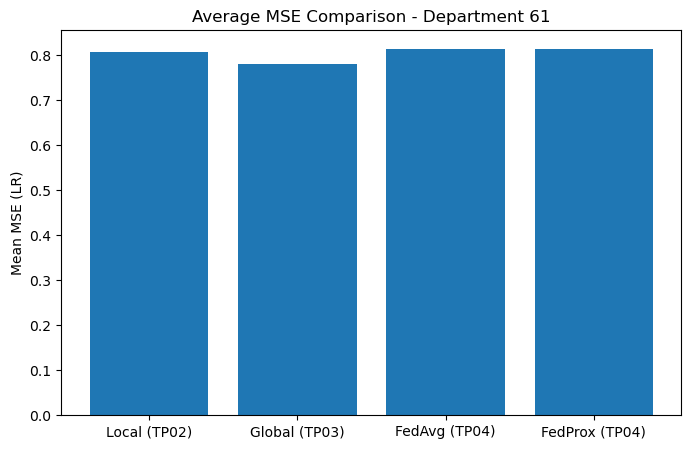

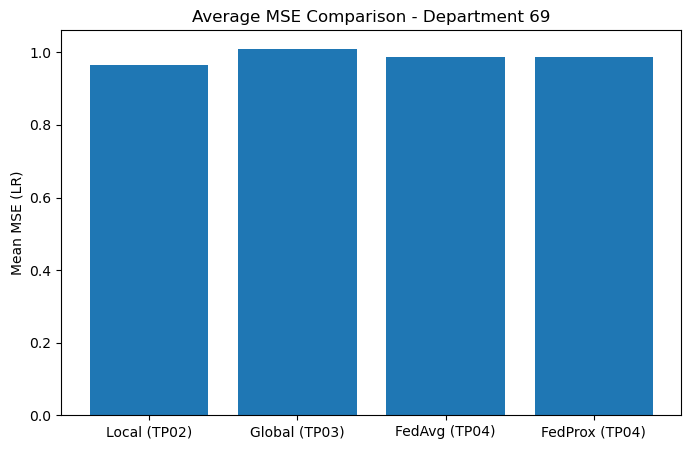

In [16]:
# AVERAGE MSE COMPARISON: Comparaison des MSE moyens entre TP02, TP03 et TP04
for dept in DEPARTMENTS:
    # Chargement des résultats TP02
    tp02 = pd.read_csv(f"local_results_DEPT_{dept}_TP02.csv")
    if "mse_lr" in tp02.columns:
        mse_local = tp02["mse_lr"].mean()  # MSE moyen local

    # Chargement des résultats TP03
    tp03 = pd.read_csv(f"results_per_station_global_model_DEPT_{dept}.csv")
    if "mse_lr_global" in tp03.columns:
        mse_global = tp03["mse_lr_global"].mean()  # MSE moyen global

    # Extraction des résultats fédérés TP04
    df_lr = lr_results[dept]
    mse_fedavg = df_lr["mse_lr_fedavg"].mean()
    mse_fedprox = df_lr["mse_lr_fedprox"].mean()

    models = ["Local (TP02)", "Global (TP03)", "FedAvg (TP04)", "FedProx (TP04)"]
    values = [mse_local, mse_global, mse_fedavg, mse_fedprox]

    plt.figure(figsize=(8, 5))

    plt.bar(models, values)
    plt.ylabel("Mean MSE (LR)")
    plt.title(f"Average MSE Comparison - Department {dept}")
    plt.show()

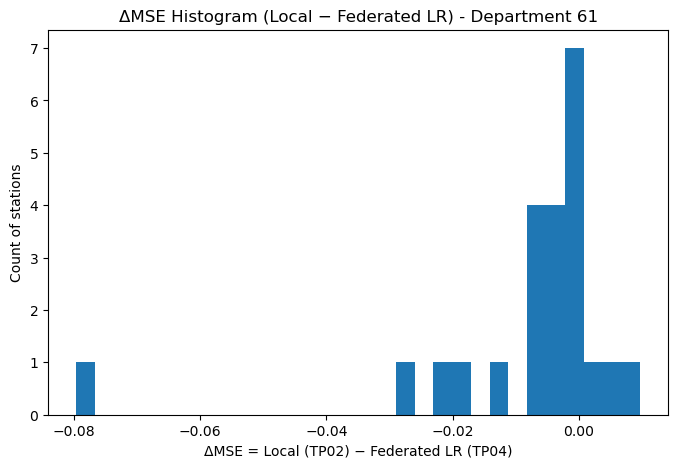

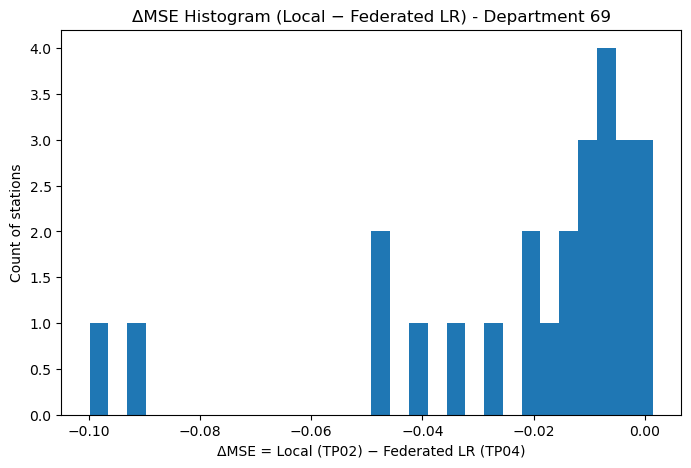

In [17]:
# DELTA MSE HISTOGRAM: Analyse des écarts entre MSE local et MSE fédéré
for dept in DEPARTMENTS:

    # Chargement des résultats TP02
    tp02 = pd.read_csv(f"local_results_DEPT_{dept}_TP02.csv")
    tp02["station_id"] = tp02["station_id"].astype(str)

    # Résultats fédérés LR
    df_lr = lr_results[dept].copy()
    df_lr["station_id"] = df_lr["station_id"].astype(str)

    # Sélection de la colonne MSE locale
    local_col = "mse_lr" if "mse_lr" in tp02.columns else "mse"

    # Fusion des données
    merged = tp02.merge(df_lr, on="station_id")

    # Différence MSE (local − fédéré)
    delta = merged[local_col] - merged["mse_lr_fedavg"]

    plt.figure(figsize=(8, 5))

    plt.hist(delta, bins=30)

    plt.xlabel("ΔMSE = Local (TP02) − Federated LR (TP04)")
    plt.ylabel("Count of stations")
    plt.title(f"ΔMSE Histogram (Local − Federated LR) - Department {dept}")
    plt.show()

Round 1/3: train MSE 0.7629
Round 2/3: train MSE 0.7629
Round 3/3: train MSE 0.7629
Round 1/3: train MSE 0.9348
Round 2/3: train MSE 0.9348
Round 3/3: train MSE 0.9348


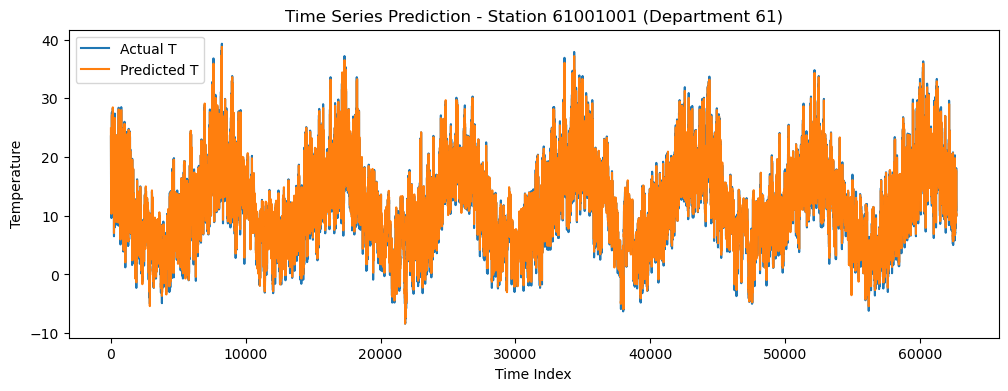

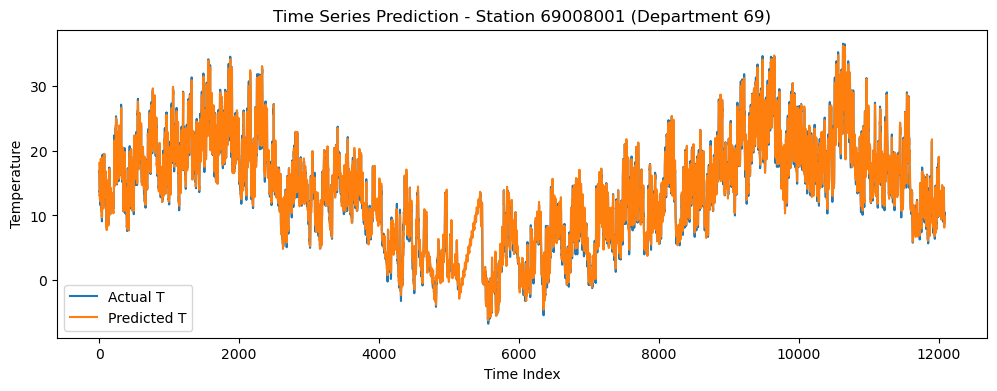

In [18]:
# TIME SERIES COMPARISON: Comparaison des séries réelles et prédites pour deux stations

# Calcul des paramètres FedAvg pour chaque département
fedavg_params = {}
for dept, dept_clients in clients.items():
    # Extraction des poids globaux (w, b)
    fedavg_params[dept] = run_federated_lr_closed(
        dept_clients,
        rounds=LR_ROUNDS,
        mu=0.0
    )[:2]

# Département 61
c61 = clients[61][0]
w61, b61 = fedavg_params[61]

y_true_61 = c61["y_test"]                     
y_pred_61 = eval_lr(w61, b61, c61["X_test"])  

plt.figure(figsize=(12, 4))
plt.plot(y_true_61)
plt.plot(y_pred_61)
plt.title(f"Time Series Prediction - Station {c61['station_id']} (Department 61)")
plt.xlabel("Time Index")
plt.ylabel("Temperature")
plt.legend(["Actual T", "Predicted T"])
plt.show()

# Département 69
c69 = clients[69][0]   
w69, b69 = fedavg_params[69]

y_true_69 = c69["y_test"]
y_pred_69 = eval_lr(w69, b69, c69["X_test"])

plt.figure(figsize=(12, 4))
plt.plot(y_true_69)
plt.plot(y_pred_69)
plt.title(f"Time Series Prediction - Station {c69['station_id']} (Department 69)")
plt.xlabel("Time Index")
plt.ylabel("Temperature")
plt.legend(["Actual T", "Predicted T"])
plt.show()